# Experiment 6: frozen FinBERT embeddings with a small CNN

This notebook tests a compact CNN using frozen FinBERT word embeddings. The TF-IDF model in `01_baseline.ipynb` remains the classical baseline.

The notebook downloads `ProsusAI/finbert` on first use. Note that this checkpoint was fine-tuned on Financial PhraseBank, so this condition is a pretrained financial representation benchmark and may contain dataset exposure.

## Imports

In [1]:
import os
os.environ["HF_HOME"] = os.path.abspath("../.cache/huggingface")
os.environ["HF_HUB_CACHE"] = os.path.abspath("../.cache/huggingface/hub")
os.makedirs(os.environ["HF_HUB_CACHE"], exist_ok=True)
import pickle
import sys

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from tensorflow import keras
from tensorflow.keras import layers
from transformers import AutoModel, AutoTokenizer

sys.path.append("..")
from utils.preprocessing import LABELS, encode_labels

keras.utils.set_random_seed(42)


## Load FinBERT embeddings and tokenize

In [2]:
train_df = pd.read_csv("../data/train.csv")
val_df = pd.read_csv("../data/val.csv")
test_df = pd.read_csv("../data/test.csv")
y_train = encode_labels(train_df.label)
y_val = encode_labels(val_df.label)
y_test = encode_labels(test_df.label)

finbert_name = "ProsusAI/finbert"
tokenizer = AutoTokenizer.from_pretrained(finbert_name)
finbert = AutoModel.from_pretrained(finbert_name)
embedding_matrix = finbert.embeddings.word_embeddings.weight.detach().cpu().numpy()

X_train = tokenizer(train_df.sentence.tolist(), padding="max_length", truncation=True, max_length=64, return_tensors="np")["input_ids"]
X_val = tokenizer(val_df.sentence.tolist(), padding="max_length", truncation=True, max_length=64, return_tensors="np")["input_ids"]
X_test = tokenizer(test_df.sentence.tolist(), padding="max_length", truncation=True, max_length=64, return_tensors="np")["input_ids"]

del finbert
print(X_train.shape, X_val.shape, X_test.shape, embedding_matrix.shape)


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

W1026 23:24:02.480000 56954 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: ProsusAI/finbert
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


(2901, 64) (967, 64) (968, 64) (30522, 768)


## Build the CNN

In [3]:
def build_cnn():
    inputs = keras.Input(shape=(64,), dtype="int32")
    x = layers.Embedding(
        embedding_matrix.shape[0],
        embedding_matrix.shape[1],
        embeddings_initializer=keras.initializers.Constant(embedding_matrix),
        trainable=False,
        mask_zero=False,
    )(inputs)
    x = layers.SpatialDropout1D(0.3)(x)
    x = layers.Conv1D(64, 3, activation="relu")(x)
    x = layers.GlobalMaxPooling1D()(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(len(LABELS), activation="softmax")(x)
    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

def evaluate(model, X, y, name):
    probabilities = model.predict(X, batch_size=32, verbose=0)
    predictions = probabilities.argmax(axis=1)
    print(name)
    print("Accuracy:", accuracy_score(y, predictions))
    print("Macro F1:", f1_score(y, predictions, average="macro"))
    print(classification_report(y, predictions, target_names=LABELS))
    ConfusionMatrixDisplay.from_predictions(y, predictions, display_labels=LABELS)
    return probabilities, predictions


## Train the model

In [5]:
cnn_model = build_cnn()
cnn_model.summary()
history = cnn_model.fit(
    X_train,
    keras.utils.to_categorical(y_train, len(LABELS)),
    validation_data=(X_val, keras.utils.to_categorical(y_val, len(LABELS))),
    epochs=20,
    batch_size=32,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 64, 768)        │    23,440,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ (None, 64, 768)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 62, 64)         │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,590,595 (89.99 MB)

 Trainable params: 149,699 (584.76 KB)

 Non-trainable params: 23,440,896 (89.42 MB)

Epoch 1/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.5760 - loss: 0.9425 - val_accuracy: 0.5936 - val_loss: 0.8828
Epoch 2/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6129 - loss: 0.8742 - val_accuracy: 0.6453 - val_loss: 0.8285
Epoch 3/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6429 - loss: 0.8113 - val_accuracy: 0.6711 - val_loss: 0.7765
Epoch 4/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6677 - loss: 0.7505 - val_accuracy: 0.6877 - val_loss: 0.7312
Epoch 5/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7156 - loss: 0.6692 - val_accuracy: 0.7156 - val_loss: 0.6693
Epoch 6/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.7715 - loss: 0.5807 - val_accuracy: 0.7373 - val_loss: 0.6410
Epoch 7/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8152 - loss: 0.4934 - val_accuracy: 0.7632 - val_loss: 0.6020
Epoch 8/20
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8452 - loss: 0.4212 - val_accuracy: 0.7797 - v

## Evaluate

Validation
Accuracy: 0.7869700103412617
Macro F1: 0.7226086183959386
              precision    recall  f1-score   support

    negative       0.82      0.51      0.63       121
     neutral       0.80      0.92      0.85       574
    positive       0.74      0.64      0.68       272

    accuracy                           0.79       967
   macro avg       0.79      0.69      0.72       967
weighted avg       0.79      0.79      0.78       967

Test
Accuracy: 0.8068181818181818
Macro F1: 0.7618280421766556
              precision    recall  f1-score   support

    negative       0.78      0.68      0.73       121
     neutral       0.81      0.93      0.87       575
    positive       0.81      0.61      0.69       272

    accuracy                           0.81       968
   macro avg       0.80      0.74      0.76       968
weighted avg       0.81      0.81      0.80       968



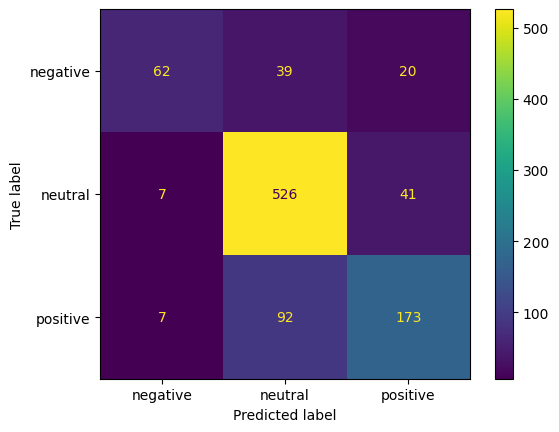

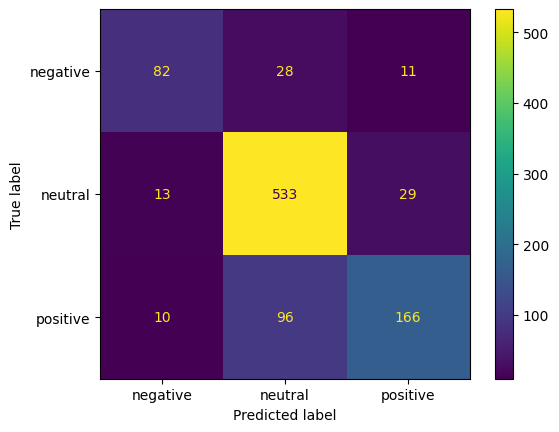

In [6]:
val_probabilities, val_predictions = evaluate(cnn_model, X_val, y_val, "Validation")
test_probabilities, test_predictions = evaluate(cnn_model, X_test, y_test, "Test")


## Save

In [7]:
# os.makedirs("../models", exist_ok=True)
# cnn_model.save("../models/experiment_6_finbert_cnn.keras")
# with open("../models/experiment_6_finbert_tokenizer.pkl", "wb") as f:
#     pickle.dump(tokenizer, f)
